# Zespół 11 — energooszczędne rozmieszczenie podów Kubernetes

Projekt MiniZinc + CBC uruchamiany w notatniku Jupyter/Kubeflow. Rozszerzenie modelu po uwagach prowadzącego.

**Cel:** zminimalizować moc aktywnych węzłów, ale uwzględnić gotowość na nowe repliki w czasie uruchamiania wyłączonej VM i preferowane rozproszenie replik.

Model optymalizuje **wszystkie pody jednocześnie** (MILP), a nie podejmuje decyzji pod po podzie jak `kube-scheduler`. Nie wykonuje operacji na rzeczywistym klastrze.

Pliki `mpi-example.mzn` i `mpi-example.dzn` powinny znajdować się w tym samym katalogu co notebook.

**Założenia:** jeden klaster z pięcioma węzłami worker (nie pięć klastrów); control plane jest zarządzany niezależnie. Węzeł ma tylko dwa stany: włączony/wyłączony. Przyjmujemy, że deklarowane `requests` CPU przybliżają faktyczne średnie wykorzystanie CPU (uproszczenie), natomiast RAM ogranicza możliwość rozmieszczenia podów. `IdlePower` obejmuje zużycie bazowe całego serwera. Dodatkowe wirtualne repliki rezerwują miejsce w planie, lecz NIE pobierają obecnie mocy. Wyniki w W są mocą; energia dla ustalonego okresu H godzin wynosi E [Wh] = P [W] × H [h].

In [1]:
from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from minizinc import Model, Solver, Instance

ROOT = Path.cwd()
MODEL = ROOT / "mpi-example.mzn"
DATA = ROOT / "mpi-example.dzn"
for path in (MODEL, DATA):
    if not path.exists():
        raise FileNotFoundError(f"Brak pliku {path}. Wgraj .mzn i .dzn do katalogu notebooka.")

try:
    solver = Solver.lookup("cbc")
    SOLVER_NAME = "cbc"
except LookupError:
    solver = Solver.lookup("highs")
    SOLVER_NAME = "highs"
print("Solver:", SOLVER_NAME)
print("Model:", MODEL.name, "| Dane:", DATA.name)

Solver: cbc
Model: mpi-example.mzn | Dane: mpi-example.dzn


## Dane wejściowe (raportowane z pliku `.dzn`)

W `mpi-example.dzn` wprowadzono różne pojemności węzłów, stały narzut na kubelet/CNI/DaemonSet i ilustracyjne wartości mocy. Nazwy miast usunięto: w projekcie jest **jeden klaster**.

In [2]:
# Prosty czytnik bazowych tablic .dzn na potrzeby raportu.
# Sam model MiniZinc otrzymuje ten sam plik bez przetwarzania przez ten czytnik.
raw_dzn = DATA.read_text(encoding="utf-8")
dzn_no_comments = re.sub(r"%[^\n]*", "", raw_dzn)

def array_1d(name):
    m = re.search(r"\b" + re.escape(name) + r"\s*=\s*\[([^\]]*)\]\s*;", dzn_no_comments, re.S)
    if not m:
        raise ValueError(f"Brak tablicy 1D {name} w .dzn")
    return [int(i) for i in re.findall(r"-?\d+", m.group(1))]

def array_2d(name):
    m = re.search(r"\b" + re.escape(name) + r"\s*=\s*\[\|(.+?)\|\]\s*;", dzn_no_comments, re.S)
    if not m:
        raise ValueError(f"Brak tablicy 2D {name} w .dzn")
    return [[int(i) for i in re.findall(r"-?\d+", row)]
            for row in m.group(1).split("|") if row.strip()]

def scalar(name):
    m = re.search(r"\b" + re.escape(name) + r"\s*=\s*(-?\d+)\s*;", dzn_no_comments)
    if not m:
        raise ValueError(f"Brak parametru {name} w .dzn")
    return int(m.group(1))

NRES = np.array(array_2d("NRes"), dtype=int)
SYSTEM = np.array(array_2d("SystemReserve"), dtype=int)
REQ = np.array(array_2d("Req"), dtype=int)
MIN_REPLICAS = np.array(array_1d("MinReplicas"), dtype=int)
IDLE = np.array(array_1d("IdlePower"), dtype=int)
MAX_POWER = np.array(array_1d("MaxPower"), dtype=int)
SHORTAGE_PENALTY = np.array(array_1d("ShortagePenalty"), dtype=int)
GROWTH = np.array(array_1d("ExtraReplicasPerMinute"), dtype=int)
BOOT_MINUTES = scalar("VMStartMinutes")
node_names = [f"Węzeł {i+1}" for i in range(len(NRES))]
m = re.search(r"\bS\s*=\s*\{(.*?)\}\s*;", dzn_no_comments, re.S)
services = [s.strip() for s in m.group(1).split(",")]
assert NRES.shape == SYSTEM.shape == (len(node_names), 2)
assert REQ.shape == (len(services), 2)
print("Węzły [CPU, RAM]:", NRES.tolist())
print("Usługi:", services, "; minimalne repliki:", MIN_REPLICAS.tolist())
print("Wymagane zasoby bazowe:", (MIN_REPLICAS @ REQ).tolist(), "[vCPU, GiB]")
print("Przyrost replik/min:", GROWTH.tolist(), "| Start VM:", BOOT_MINUTES, "min")

Węzły [CPU, RAM]: [[24, 96], [48, 176], [16, 64], [12, 48], [28, 112]]
Usługi: ['WEB', 'DB'] ; minimalne repliki: [16, 10]
Wymagane zasoby bazowe: [36, 112] [vCPU, GiB]
Przyrost replik/min: [2, 1] | Start VM: 3 min


In [3]:
def stats_from_placement(alloc, active=None):
    """Fizyczna moc i wolne zasoby po umieszczeniu REALNYCH podów.
    Rezerwa standby jest WIRTUALNA i nie jest liczona jako bieżące użycie CPU.
    """
    alloc = np.array(alloc, dtype=int)
    if active is None:
        active = (alloc.sum(axis=0) > 0).astype(int)
    active = np.array(active, dtype=int)
    used = alloc.T @ REQ  # [node, (cpu,ram)]
    available = (NRES - SYSTEM) * active[:, None]
    free = available - used
    node_power = active * IDLE + (MAX_POWER-IDLE)*used[:,0]/NRES[:,0]
    return dict(used=used, free=free, node_power=node_power,
                total_power=float(node_power.sum()), active=active)


def power_from_result(solution):
    """Oblicza szacowaną fizyczną moc [W] z x i is_active.

    Nie wymaga pola total_power w wynikach MiniZinc.
    """
    return stats_from_placement(solution["x"], solution["is_active"])["total_power"]


def objective_from_result(solution, penalty_percent=100, spread_penalty=4):
    """Zwraca funkcję celu [W-ekw.] z API MiniZinc lub z jej składowych.

    Kary nie są rzeczywistą mocą. Fallback działa także, gdy
    objective nie jest udostępnione przez wersję wrappera/solvera.
    """
    obj = getattr(solution, "objective", None)
    if obj is not None:
        return float(obj)

    x = np.array(solution["x"], dtype=int)
    shortage = np.array(solution["shortage"], dtype=int)
    reserve_penalty = (penalty_percent / 100.0) * float(shortage @ SHORTAGE_PENALTY)
    spread_cost = float(spread_penalty * np.maximum(x - 1, 0).sum())
    return power_from_result(solution) + reserve_penalty + spread_cost


## Funkcja celu i ograniczenia

\[
\min\left\{
 \underbrace{\sum_n [P_n^{idle} a_n + (P_n^{max}-P_n^{idle})\,CPU_n/CPU_n^{cap}]}_{\text{rzeczywista szacowana moc [W]}}
 + \underbrace{\lambda\sum_s q_s\,brak_s}_{\text{kara za brak miejsca na dodatkowe repliki}}
 + \underbrace{\gamma\sum_{s,n}\max(0,x_{s,n}-1)}_{\text{preferencja rozproszenia}}
\right\}.
\]

- `standby[s,n]` to **wirtualne miejsca** dla dodatkowych podów, które mogą wystartować szybko, zanim nowa VM dołączy do klastra. Nie są to działające pody i nie zwiększają bieżącej mocy.
- `shortage[s]` to liczba prognozowanych dodatkowych replik, na które **brakuje miejsca** na aktywnych węzłach. Kara jest miękka — naruszenie oznacza ryzyko opóźnienia skalowania, nie brak istniejącej usługi.
- `ReserveScale` zwiększa skalę prognozowanego burstu. `ShortagePenaltyMultiplier` steruje ceną gotowości, a `SpreadPenalty` jest miękką karą za skupienie replik.
- Ograniczenie na `SystemReserve` odejmuje zasoby kubelet/CNI/DaemonSet od zasobów dostępnych dla aplikacji. Model nie dopuszcza uruchamiania usług na wyłączonym węźle.

**Uwaga:** kary są w jednostkach umownych **W-ekwiwalent**. `result.objective` reprezentuje wartość celu (moc + kary), a fizyczną szacowaną moc oblicza funkcja `power_from_result(result)` na podstawie `x` i `is_active`. Wersja MiniZinc/Python nie zawsze zwraca `total_power` lub `total_objective` jako pola wyniku.

In [4]:
# Do scenariuszy zmieniamy wyłącznie trzy parametry w danych.
# Pozostałe ustawienia (w tym Req, pojemności, overhead) są identyczne.
def updated_data(reserve_scale=1, penalty_percent=100, spread_penalty=4):
    txt = raw_dzn
    for key, value in {
        "ReserveScale": reserve_scale,
        "ShortagePenaltyMultiplier": penalty_percent,
        "SpreadPenalty": spread_penalty,
    }.items():
        pattern = rf"(?m)^(\s*{key}\s*=\s*)\d+(\s*;)"
        txt, count = re.subn(pattern, lambda mm: mm.group(1) + str(int(value)) + mm.group(2), txt)
        if count != 1:
            raise ValueError(f"Oczekiwano dokładnie jednego parametru {key}, znaleziono: {count}")
    return txt

async def run_case(reserve_scale=1, penalty_percent=100, spread_penalty=4, hard_reserve=False):
    model = Model(str(MODEL))
    if hard_reserve:
        model.add_string("constraint forall(s in S)(shortage[s] = 0);")
    model.add_string(updated_data(reserve_scale, penalty_percent, spread_penalty))
    instance = Instance(solver, model)
    result = await instance.solve_async()  # bez free_search: dla CBC nie jest to tryb profilowania
    if not result.status.has_solution():
        raise RuntimeError(f"Brak rozwiązania: {result.status}")
    return result

# Rozwiązanie bazowe: rezerwa dla burstu w czasie rozruchu VM
result = await run_case(reserve_scale=1, penalty_percent=100, spread_penalty=4)
print("Status:", result.status)
print("Moc [W]:", round(power_from_result(result), 2))
print("Cel [W-ekw.]:", round(objective_from_result(result, penalty_percent=100, spread_penalty=4), 2))

Status: OPTIMAL_SOLUTION
Moc [W]: 392.0
Cel [W-ekw.]: 488.0


In [5]:
x = np.array(result["x"], dtype=int)
a = np.array(result["is_active"], dtype=int)
standby = np.array(result["standby"], dtype=int)
shortage = np.array(result["shortage"], dtype=int)
info = stats_from_placement(x, a)
# Sprawdzenia zgodności rozwiązania z ograniczeniami modelu
assert np.all(info["free"] >= 0), "Pod przekracza zasoby węzła"
assert np.all(info["free"] >= standby.T @ REQ), "Za mało miejsca na standby"
assert np.array_equal(x.sum(axis=1), MIN_REPLICAS), "Nieprawidłowa liczba bazowych replik"
assert np.array_equal(standby.sum(axis=1) + shortage, BOOT_MINUTES * GROWTH), "Nieprawidłowy bilans zapasu"
assert not np.any((a == 0) & (x.sum(axis=0) + standby.sum(axis=0) > 0)), "Pody na wyłączonym węźle"

print("\n=== WYNIK OPTYMALIZACJI ===")
print(f"Aktywne węzły: {sum(a)} / {len(a)}")
print(f"Moc: {info['total_power']:.2f} W | Energia przez 1 h: {info['total_power']:.2f} Wh")
print(f"Cel (wraz z karami): {objective_from_result(result, penalty_percent=100, spread_penalty=4):.2f} W-ekw.")
print("Brak miejsca na dodatkowe repliki:", dict(zip(services, shortage.tolist())))
print("\nWęzeł        aktywny    CPU użyte/dost.     RAM użyte/dost.    wolny CPU/RAM    P[W]")
for n, label in enumerate(node_names):
    allocatable = NRES[n] - SYSTEM[n]
    v = info['used'][n]
    print(f"{label:<13} {a[n]:>3}       {v[0]:>2}/{allocatable[0]:<2} vCPU       "
          f"{v[1]:>3}/{allocatable[1]:<3} GiB     "
          f"{info['free'][n,0]:>2}/{info['free'][n,1]:<3}        {info['node_power'][n]:>7.2f}")
print("\nREALNE POD-y:")
for s, name in enumerate(services):
    print(f"  {name:6s}:", dict(zip(node_names, x[s].tolist())))
print("WIRTUALNY ZAPAS (miejsca na nowe pody):")
for s, name in enumerate(services):
    print(f"  {name:6s}:", dict(zip(node_names, standby[s].tolist())))

print("\n=== STATYSTYKI SOLVERA ===")
for key, value in result.statistics.items():
    print(f"{str(key):24s} {value}")


=== WYNIK OPTYMALIZACJI ===
Aktywne węzły: 2 / 5
Moc: 392.00 W | Energia przez 1 h: 392.00 Wh
Cel (wraz z karami): 488.00 W-ekw.
Brak miejsca na dodatkowe repliki: {'WEB': 0, 'DB': 0}

Węzeł        aktywny    CPU użyte/dost.     RAM użyte/dost.    wolny CPU/RAM    P[W]
Węzeł 1         0        0/23 vCPU         0/92  GiB      0/0             0.00
Węzeł 2         1       36/47 vCPU       112/172 GiB     11/60          330.00
Węzeł 3         0        0/15 vCPU         0/60  GiB      0/0             0.00
Węzeł 4         1        0/11 vCPU         0/44  GiB     11/44           62.00
Węzeł 5         0        0/27 vCPU         0/108 GiB      0/0             0.00

REALNE POD-y:
  WEB   : {'Węzeł 1': 0, 'Węzeł 2': 16, 'Węzeł 3': 0, 'Węzeł 4': 0, 'Węzeł 5': 0}
  DB    : {'Węzeł 1': 0, 'Węzeł 2': 10, 'Węzeł 3': 0, 'Węzeł 4': 0, 'Węzeł 5': 0}
WIRTUALNY ZAPAS (miejsca na nowe pody):
  WEB   : {'Węzeł 1': 0, 'Węzeł 2': 5, 'Węzeł 3': 0, 'Węzeł 4': 1, 'Węzeł 5': 0}
  DB    : {'Węzeł 1': 0, 'Węzeł 2'

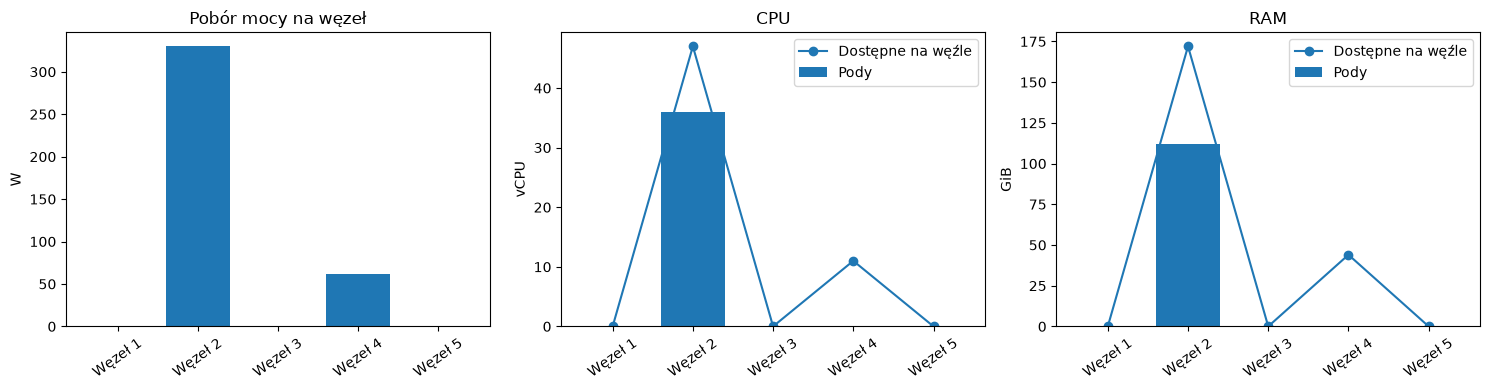

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(node_names, info['node_power'])
axes[0].set_title("Pobór mocy na węzeł")
axes[0].set_ylabel("W")
axes[1].bar(node_names, info['used'][:,0], label="Pody")
axes[1].plot(node_names, (NRES-SYSTEM)[:,0] * a, marker='o', label="Dostępne na węźle")
axes[1].set_title("CPU")
axes[1].set_ylabel("vCPU")
axes[1].legend()
axes[2].bar(node_names, info['used'][:,1], label="Pody")
axes[2].plot(node_names, (NRES-SYSTEM)[:,1] * a, marker='o', label="Dostępne na węźle")
axes[2].set_title("RAM")
axes[2].set_ylabel("GiB")
axes[2].legend()
for ax in axes:
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()

## Eksperyment A — ile kosztuje zapas na szybkie skalowanie?

`ReserveScale=0`: optymalizujemy bez wymaganego burstu. `1`: prognoza na 3 min rozruchu VM. `2`, `3`: większy szacowany wzrost ruchu. Pokazujemy osobno **moc [W]**, **liczbę węzłów** i **brakujące repliki**, a nie tylko wartość ważonej funkcji celu.

Skala | Aktywne węzły | Moc [W] | Brak replik | Wartość celu [W-ekw.]
    0 |              1 |  330.00 |           0 |       426.00
    1 |              2 |  392.00 |           0 |       488.00
    2 |              2 |  408.54 |           0 |       500.54
    3 |              2 |  455.54 |           0 |       543.54


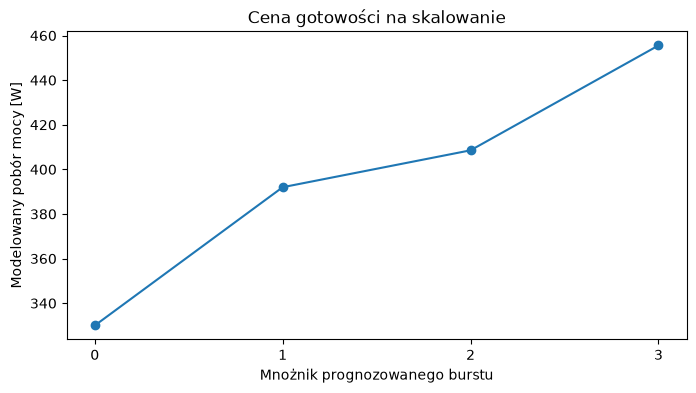

In [7]:
reserve_rows=[]
for scale in [0, 1, 2, 3]:
    r = await run_case(reserve_scale=scale, penalty_percent=100, spread_penalty=4)
    aa = np.array(r['is_active'], dtype=int)
    gap = np.array(r['shortage'], dtype=int)
    reserve_rows.append(dict(skala=scale, wezly=int(sum(aa)),
                             moc_W=power_from_result(r),
                             brak_replik=int(sum(gap)),
                             cel=objective_from_result(r, penalty_percent=100, spread_penalty=4)))
print("Skala | Aktywne węzły | Moc [W] | Brak replik | Wartość celu [W-ekw.]")
for row in reserve_rows:
    print(f"{row['skala']:>5} | {row['wezly']:>14} | {row['moc_W']:>7.2f} | "
          f"{row['brak_replik']:>11} | {row['cel']:>12.2f}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([r['skala'] for r in reserve_rows], [r['moc_W'] for r in reserve_rows], marker='o')
ax.set_xticks([0,1,2,3])
ax.set_xlabel("Mnożnik prognozowanego burstu")
ax.set_ylabel("Modelowany pobór mocy [W]")
ax.set_title("Cena gotowości na skalowanie")
plt.show()

## Eksperyment B — twardy zapas czy miękka kara?

W modelu wybrano **miękką** ochronę gotowości, ponieważ nie mamy bezwzględnego wymagania, aby natychmiast obsłużyć każdą prognozowaną replikę. `ShortagePenaltyMultiplier=0` oznacza brak kary; 100 to bazowa kara; 200 — podwojona. Gdy wymagana gotowość jest twardym SLA, należy zastąpić to warunkiem `shortage[s] = 0` dla wymaganych usług i sprawdzić wykonalność.

Kara [%] | Moc [W] | Aktywne węzły | Brak miejsc
       0 |  330.00 |              1 |          9
      25 |  330.00 |              1 |          1
      50 |  330.00 |              1 |          1
     100 |  392.00 |              2 |          0
     200 |  392.00 |              2 |          0


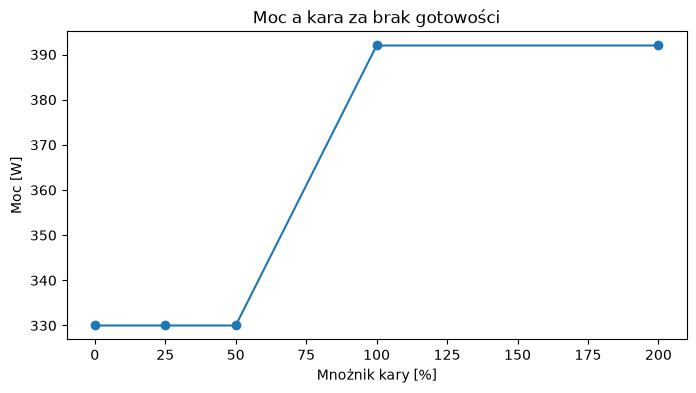

In [8]:
penalty_rows=[]
for penalty in [0, 25, 50, 100, 200]:
    r = await run_case(reserve_scale=1, penalty_percent=penalty, spread_penalty=4)
    penalty_rows.append((penalty, power_from_result(r),
                         int(sum(r['is_active'])), int(sum(r['shortage']))))
print("Kara [%] | Moc [W] | Aktywne węzły | Brak miejsc")
for row in penalty_rows:
    print(f"{row[0]:>8} | {row[1]:>7.2f} | {row[2]:>14} | {row[3]:>10}")
fig, ax = plt.subplots(figsize=(8,4))
ax.plot([r[0] for r in penalty_rows], [r[1] for r in penalty_rows], marker='o', label="Moc [W]")
ax.set_xlabel("Mnożnik kary [%]")
ax.set_ylabel("Moc [W]")
ax.set_title("Moc a kara za brak gotowości")
plt.show()

### Dodatkowy wariant: wymaganie twarde (zero brakujących miejsc)

Można uruchomić to samo MILP z ograniczeniem `shortage[s] = 0` dla każdej usługi. Porównujemy je z miękką karą na 25%, gdzie solver może jeszcze dopuścić niedobór gotowości.

In [9]:
soft = await run_case(reserve_scale=1, penalty_percent=25, spread_penalty=4)
hard = await run_case(reserve_scale=1, penalty_percent=25, spread_penalty=4, hard_reserve=True)
print(f"Miękka rezerwa: moc {power_from_result(soft):.2f} W, "
      f"brak {sum(soft['shortage'])} dodatkowych replik")
print(f"Twarda rezerwa: moc {power_from_result(hard):.2f} W, "
      f"brak {sum(hard['shortage'])} dodatkowych replik")

Miękka rezerwa: moc 330.00 W, brak 1 dodatkowych replik
Twarda rezerwa: moc 392.00 W, brak 0 dodatkowych replik


## Strategie `NodeResourcesFit` — porównanie poglądowe

Dokumentacja Kubernetes opisuje plugin `NodeResourcesFit` w etapach **Filter** (czy pod mieści się na węźle) i **Score** (punktowanie dopuszczalnych węzłów). Obsługiwane są `LeastAllocated` (domyślna strategia), `MostAllocated` i `RequestedToCapacityRatio` (punkty określa konfigurowana krzywa). Rozmieszczenie rzeczywistego schedulera zależy też od pozostałych pluginów i kolejności przychodzenia podów.

Poniżej jest **uproszczona symulacja** tych strategii, NIE implementacja `kube-scheduler`: planujemy pody kolejno, porównujemy uśrednione wykorzystanie CPU/RAM po przydziale, a po zakończeniu wyłączamy węzły, na których nie ma podów. Wszystkie 5 węzłów są potencjalnie gotowe podczas samego rozmieszczania, a liczba użytych później zależy od wyniku. Symulacja nie realizuje rozruchu ani preempcji i porównuje wyłącznie rozkład podstawowych replik.

Globalne odpowiedniki celów: `LeastAllocated` preferuje mniejsze obciążenia (np. minimalizację najwyższego wykorzystania), `MostAllocated` preferuje upakowanie (np. minimalizację liczby aktywnych węzłów), a `RequestedToCapacityRatio` maksymalizuje zdefiniowaną przez operatora funkcję kształtu obciążenia. Te globalne cele nie są dokładnie równoważne punktowaniu pod po podzie.

Źródło: [Scheduler Configuration](https://kubernetes.io/docs/reference/scheduling/config/).

In [10]:
def shape_ratio(z):
    """Przykładowa, AUTORSKA krzywa RequestedToCapacityRatio:
    0% -> 0, 25% -> 100, 60% -> 50, 100% -> 0.
    Nie jest to domyślna krzywa Kubernetes.
    """
    return float(np.interp(z, [0, .25, .6, 1], [0, 100, 50, 0]))

def greedy_schedule(strategy):
    # Stała, deterministyczna kolejność przyjść: WEB, DB naprzemiennie,
    # a później pozostałe WEB. Nie optymalizujemy kolejności.
    allocation = np.zeros((len(services), len(node_names)), dtype=int)
    allocated = (NRES - SYSTEM)
    sequence = [s for i in range(max(MIN_REPLICAS))
                for s in range(len(services)) if i < MIN_REPLICAS[s]]
    for s in sequence:
        occupied = allocation.T @ REQ
        candidates = []
        for n in range(len(node_names)):
            projected = occupied[n] + REQ[s]
            if np.any(projected > allocated[n]):
                continue
            util = projected / allocated[n]
            if strategy == 'LeastAllocated':
                score = -float(util.mean())
            elif strategy == 'MostAllocated':
                score = float(util.mean())
            elif strategy == 'RequestedToCapacityRatio':
                score = (shape_ratio(util[0]) + shape_ratio(util[1])) / 2
            else:
                raise ValueError(strategy)
            candidates.append((score, -n, n))  # deterministyczny tie-break
        if not candidates:
            raise RuntimeError(f"Strategia {strategy}: brak miejsca na {services[s]}")
        _, _, n = max(candidates)
        allocation[s,n] += 1
    return allocation

# Przybliżona (greedy) ocena, ile dodatkowych replik można od razu zmieścić
# na już aktywnych węzłach; może nie być optymalna.
def greedy_shortage(placement, scale=1):
    stat = stats_from_placement(placement)
    free = stat['free'].copy()
    missing = np.zeros(len(services), dtype=int)
    burst = scale * BOOT_MINUTES * GROWTH
    for s in sorted(range(len(services)), key=lambda s: -REQ[s,1]):
        for _ in range(int(burst[s])):
            fit = [n for n in range(len(node_names))
                   if stat['active'][n] and np.all(free[n] >= REQ[s])]
            if not fit:
                missing[s] += 1
            else:
                n = min(fit, key=lambda n: (free[n,0]-REQ[s,0])+(free[n,1]-REQ[s,1])/4)
                free[n] -= REQ[s]
    return missing

base_milp = await run_case(reserve_scale=0, penalty_percent=100, spread_penalty=0)
base_a = np.array(base_milp['is_active'], dtype=int)
print(f"MILP bez zapasu i bez kar: {sum(base_a)} aktywnych węzłów, "
      f"moc {power_from_result(base_milp):.2f} W")
print("Strategia                     | węzły | moc [W] | wolne vCPU | wolne GiB | brak miejsc* ")
for strategy in ['LeastAllocated', 'MostAllocated', 'RequestedToCapacityRatio']:
    alloc = greedy_schedule(strategy)
    r = stats_from_placement(alloc)
    gap = greedy_shortage(alloc, scale=1)
    print(f"{strategy:<30} | {sum(r['active']):>5} | {r['total_power']:>7.2f} | "
          f"{r['free'][:,0].sum():>10} | {r['free'][:,1].sum():>9} | {sum(gap):>12}")
    print("  POD-y:", {name: alloc[i].tolist() for i, name in enumerate(services)})

print("* Brak miejsc: przybliżona ocena greedy dla burstu na AKTYWNYCH węzłach.")
print("  MILP wyznacza standby i shortage optymalnie w ramach funkcji celu.")

MILP bez zapasu i bez kar: 1 aktywnych węzłów, moc 330.00 W
Strategia                     | węzły | moc [W] | wolne vCPU | wolne GiB | brak miejsc* 
LeastAllocated                 |     5 |  755.22 |         87 |       364 |            0
  POD-y: {'WEB': [3, 3, 5, 3, 2], 'DB': [2, 5, 0, 0, 3]}
MostAllocated                  |     3 |  533.71 |         13 |        84 |            0
  POD-y: {'WEB': [6, 0, 5, 5, 0], 'DB': [2, 0, 5, 3, 0]}
RequestedToCapacityRatio       |     3 |  523.79 |         13 |        84 |            0
  POD-y: {'WEB': [9, 0, 3, 4, 0], 'DB': [4, 0, 4, 2, 0]}
* Brak miejsc: przybliżona ocena greedy dla burstu na AKTYWNYCH węzłach.
  MILP wyznacza standby i shortage optymalnie w ramach funkcji celu.


## Omówienie pozostałych uwag prowadzącego

- **Czy `sum_s x[s,n] >= is_active[n]` coś zmienia?** Tak: wymusza, aby włączony węzeł miał pod aplikacyjny. Usunęliśmy to ograniczenie, żeby móc utrzymywać włączoną VM z wolnym miejscem na burst. Dodatnia `IdlePower` sprawia, że solver nie uruchamia bezużytecznego węzła.
- **Liczba replik:** `sum_n x[s,n] == MinReplicas[s]` — stała liczba bazowych podów. Min. repliki w rzeczywistości chronią dostępność i obsługę ruchu; sam model nie zapewnia HA, dlatego jest miękka kara za współlokację.
- **Nie każda replika innej usługi to to samo:** `Req[s,CPU]`, `Req[s,RAM]` oraz wzrost liczby replik w czasie startu VM są specyficzne dla usługi.
- **Kiedy kara miękka, kiedy twarda?** Prognoza burstu jest niepewna: miękka kara pozwala pokazać koszt gotowości. Jeżeli usługa ma ścisłe SLA, jej brak miejsc powinien być ograniczony twardo do zera.
- **`MaxReplicas` nie jest limitem klastra:** techniczna górna granica zmiennej wynikająca z danych; osobny warunek `x[s,n] <= MinReplicas[s]` i równość sumy wyznaczają rzeczywisty przydział.
- **Control plane i narzut:** optymalizujemy wyłącznie workery. `SystemReserve` rezerwuje zasoby każdego aktywnego workera na kubelet, CNI i DaemonSet. Nie próbujemy wyłączać control plane.
- **Moc a energia:** pojedyncze rozwiązanie minimalizuje moc w stałym profilu obciążenia, a przez okres `H` godzin daje energię `E = P×H` [Wh]. Rozruch VM, koszt przełączeń, czasowy przebieg obciążenia i migracje są poza modelem.
- **Overprovisioning w praktyce:** można utrzymywać niskopriorytetowe pody-zastępniki (`pause`), które rezerwują zasoby i są wywłaszczane przez prawdziwe pody; Cluster Autoscaler może potem zwiększać liczbę węzłów. `standby[s,n]` to abstrakcyjne odwzorowanie takiego zapasu, nie faktyczne pody uruchamiane przez ten notebook.
- **Miękkie rozproszenie:** odpowiednikiem jest m.in. `preferredDuringSchedulingIgnoredDuringExecution` w podAntiAffinity lub `ScheduleAnyway` w topologySpreadConstraints; nasze liniowe `colocated` jest uproszczeniem ich preferencji.

Dokumentacja: [Kubernetes Node overprovisioning](https://kubernetes.io/docs/tasks/administer-cluster/node-overprovisioning/) · [Cluster Autoscaler FAQ](https://github.com/kubernetes/autoscaler/blob/master/cluster-autoscaler/FAQ.md) · [Topology Spread](https://kubernetes.io/docs/concepts/scheduling-eviction/topology-spread-constraints/) · [Assign Pods to Nodes](https://kubernetes.io/docs/concepts/scheduling-eviction/assign-pod-node/).